In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.style.use("seaborn-v0_8-whitegrid")

contributors = pd.read_csv("contributors.csv")
monthly = pd.read_csv("monthly.csv")
weekly = pd.read_csv("weekly.csv")

columns = [
    "tenure_days", "recency_days", "count_window",
    "active_weeks", "mean_gap_days_window"
]

for column in columns:
    contributors[column] = pd.to_numeric(
        contributors[column], errors="coerce"
    )


# True excludes accounts flagged as possible bots by the collector.
# This is a heuristic: manually check borderline cases for your report.
EXCLUDE_BOT_CANDIDATES = True

if EXCLUDE_BOT_CANDIDATES:
    is_bot = (
        contributors["bot_candidate"]
        .astype(str)
        .str.lower()
        .isin(["true", "1"])
    )
    print(f"Excluding {is_bot.sum()} bot-candidate identities.")
    contributors = contributors.loc[~is_bot].copy()


# Apply the SAME contributor selection to the monthly data.
monthly = monthly[
    monthly["contributor_id"].isin(contributors["contributor_id"])
].copy()

if contributors.empty:
    raise ValueError("No contributors remain after filtering.")

Excluding 11 bot-candidate identities.


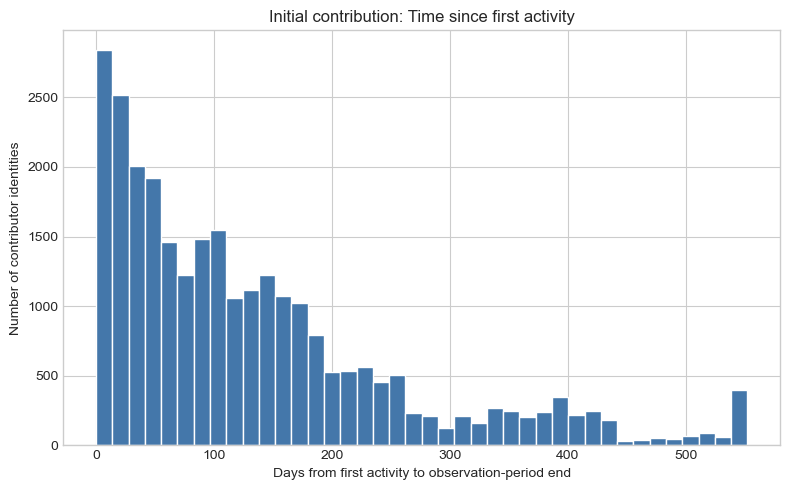

In [2]:
plt.figure(figsize=(8, 5))
plt.hist(contributors["tenure_days"].dropna(),
         bins=40, color="#4477AA", edgecolor="white")
plt.title("Initial contribution: Time since first activity")
plt.xlabel("Days from first activity to observation-period end")
plt.ylabel("Number of contributor identities")
plt.tight_layout()
plt.show()

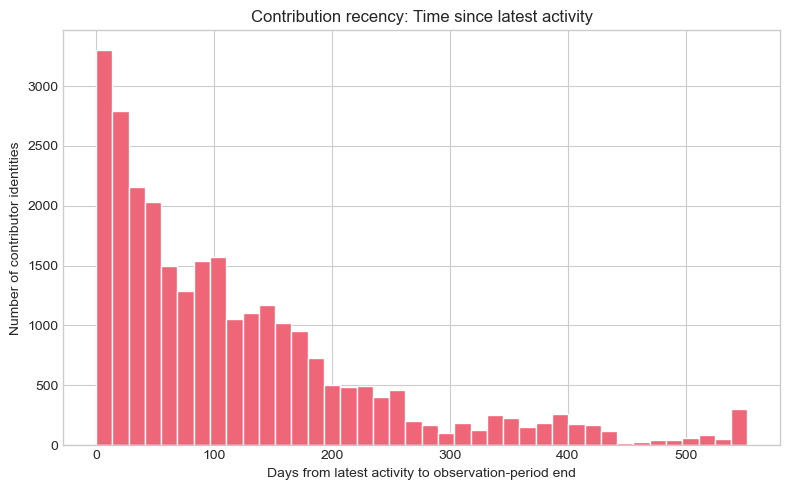

In [3]:
plt.figure(figsize=(8, 5))
plt.hist(contributors["recency_days"].dropna(),
         bins=40, color="#EE6677", edgecolor="white")
plt.title("Contribution recency: Time since latest activity")
plt.xlabel("Days from latest activity to observation-period end")
plt.ylabel("Number of contributor identities")
plt.tight_layout()
plt.show()

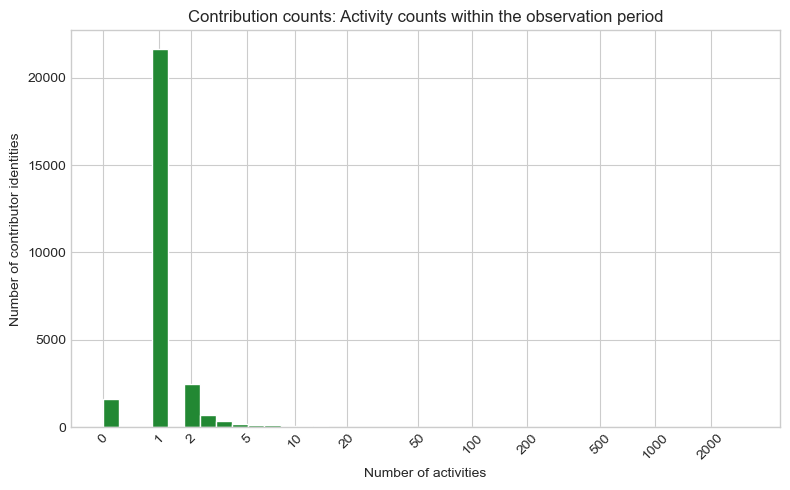

In [4]:
counts = contributors["count_window"].dropna()

plt.figure(figsize=(8, 5))
plt.hist(np.log1p(counts),
         bins=40, color="#228833", edgecolor="white")

ticks = [0, 1, 2, 5, 10, 20, 50, 100, 200, 500,
         1000, 2000, 5000, 10000, 20000, 50000]
ticks = [value for value in ticks if value <= counts.max()]
plt.xticks(np.log1p(ticks), ticks, rotation=45)

plt.title("Contribution counts: Activity counts within the observation period")
plt.xlabel("Number of activities")
plt.ylabel("Number of contributor identities")
plt.tight_layout()
plt.show()

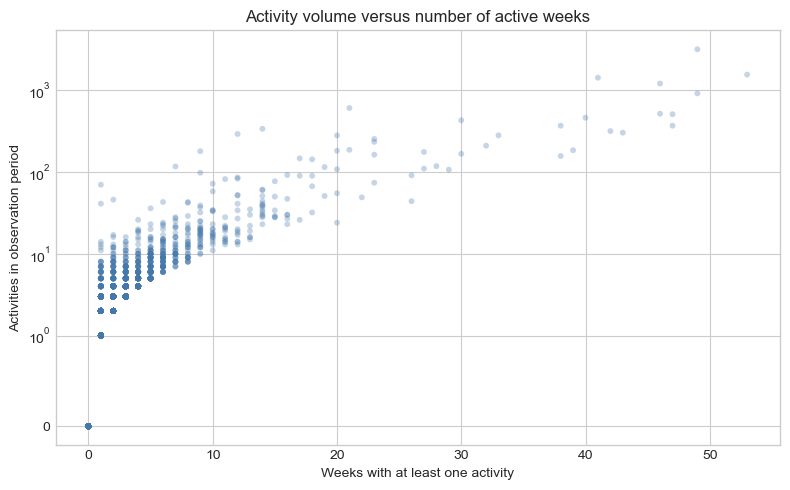

In [5]:
plt.figure(figsize=(8, 5))
plt.scatter(
    contributors["active_weeks"],
    contributors["count_window"],
    alpha=0.3, s=18, color="#4477AA", edgecolors="none"
)
plt.yscale("symlog", linthresh=1)
plt.title("Activity volume versus number of active weeks")
plt.xlabel("Weeks with at least one activity")
plt.ylabel("Activities in observation period")
plt.tight_layout()
plt.show()

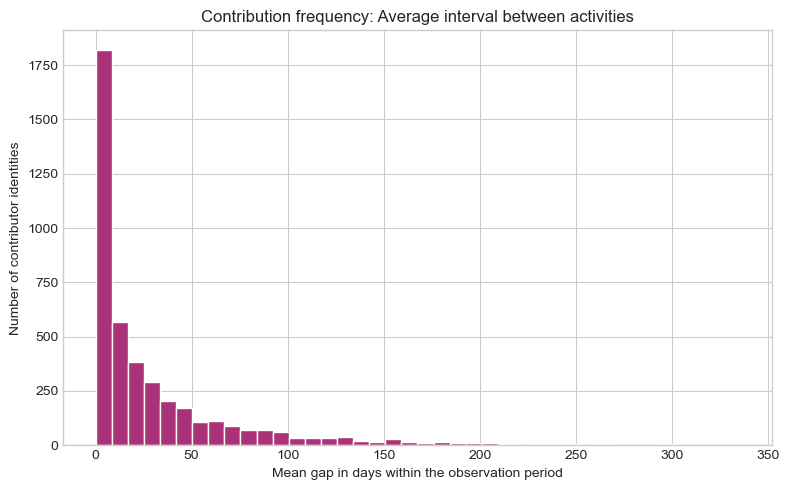

Contributors excluded because their gap is undefined: 23254


In [6]:
gaps = contributors["mean_gap_days_window"].dropna()

plt.figure(figsize=(8, 5))
plt.hist(gaps, bins=40, color="#AA3377", edgecolor="white")
plt.title("Contribution frequency: Average interval between activities")
plt.xlabel("Mean gap in days within the observation period")
plt.ylabel("Number of contributor identities")
plt.tight_layout()
plt.show()

print(
    "Contributors excluded because their gap is undefined:",
    contributors["mean_gap_days_window"].isna().sum()
)

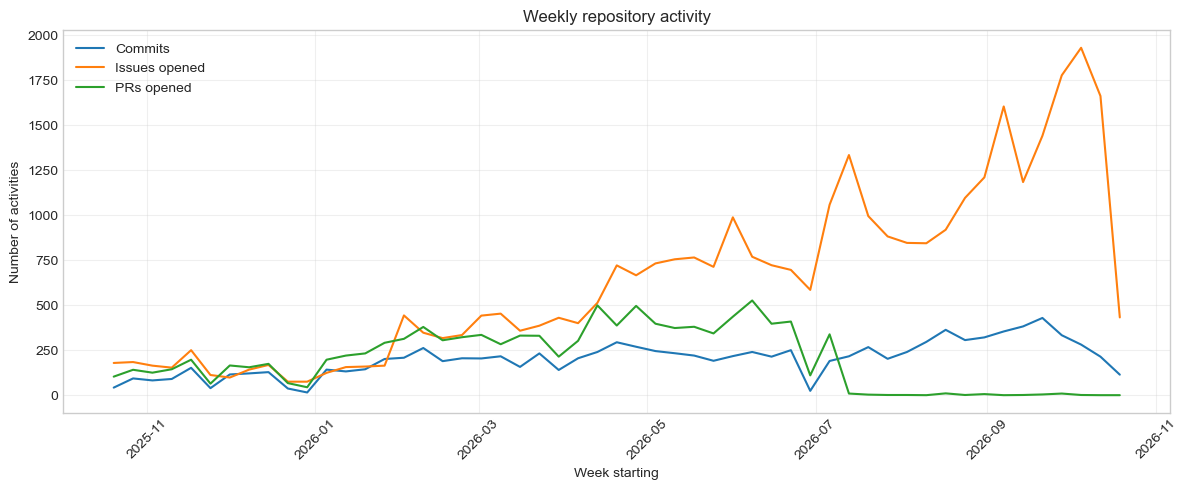

In [7]:
weekly = pd.read_csv("weekly.csv")

# Keep the same contributors (including any bot exclusions).
weekly = weekly[
    weekly["contributor_id"].isin(contributors["contributor_id"])
].copy()

weekly["period_start"] = pd.to_datetime(weekly["period_start"], utc=True)

counts = ["commit_count", "issue_opened_count", "pr_opened_count"]
weekly_totals = weekly.groupby("period_start")[counts].sum().sort_index()

plt.figure(figsize=(12, 5))
for column, label in zip(counts, ["Commits", "Issues opened", "PRs opened"]):
    plt.plot(weekly_totals.index, weekly_totals[column], label=label)

plt.xlabel("Week starting")
plt.ylabel("Number of activities")
plt.title("Weekly repository activity")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [8]:
events = pd.read_csv("events.csv")
events["timestamp"] = pd.to_datetime(events["timestamp"], utc=True)

display(
    events.groupby("activity_type")["timestamp"]
    .agg(records="count", earliest="min", latest="max")
)

,records,earliest,latest
activity_type,,,
commit,12446,2025-04-16 16:56:08+00:00,2026-10-20 23:42:20+00:00
issue_opened,36306,2025-04-16 17:27:52+00:00,2026-10-20 23:49:45+00:00
pr_opened,17822,2025-04-16 16:59:21+00:00,2026-10-20 23:42:24+00:00


In [9]:
import json
from pathlib import Path

files = sorted(Path("cache").glob("openings_v3_*.json"))

if files:
    last = json.loads(files[-1].read_text())
    dates = [item["created_at"] for item in last["items"]]

    print("Last cached batch:", files[-1].name)
    print("Records in batch:", len(dates))
    print("Latest creation date:", max(dates) if dates else "Empty")
    print("Next-page link:", last.get("next_path"))
else:
    print("No v3 issue/PR cache files found.")

Last cached batch: openings_v3_000303.json
Records in batch: 13
Latest creation date: 2026-07-06T08:29:40Z
Next-page link: None


In [10]:
events_check = pd.read_csv("events.csv")
events_check["timestamp"] = pd.to_datetime(
    events_check["timestamp"], utc=True
)

start = pd.Timestamp("2025-10-22", tz="UTC")
end = pd.Timestamp("2026-10-21", tz="UTC")

window = events_check.loc[
    (events_check["timestamp"] >= start)
    & (events_check["timestamp"] < end)
].copy()

print("Duplicate event IDs:", window["event_id"].duplicated().sum())

window["month"] = window["timestamp"].dt.strftime("%Y-%m")
months = pd.date_range(
    "2025-10-01", "2026-10-01", freq="MS"
).strftime("%Y-%m")

types = ["commit", "issue_opened", "pr_opened"]

def monthly_counts(data):
    return (
        pd.crosstab(data["month"], data["activity_type"])
        .reindex(index=months, columns=types, fill_value=0)
    )

all_counts = monthly_counts(window)
selected_counts = monthly_counts(
    window[window["contributor_id"].isin(contributors["contributor_id"])]
)

display(pd.concat(
    {"All exported events": all_counts,
     "After notebook filtering": selected_counts},
    axis=1
))

Duplicate event IDs: 0


All exported events                         \
activity_type              commit issue_opened pr_opened   
2025-10                       138          316       230   
2025-11                       377          726       567   
2025-12                       427          523       611   
2026-01                       642          618       990   
2026-02                       888         1431      1345   
2026-03                       848         1785      1364   
2026-04                      1073         2354      1746   
2026-05                       939         3227      1611   
2026-06                       930         3410      1813   
2026-07                       879         4403      1137   
2026-08                      1262         4074      1170   
2026-09                      1596         6072      1613   
2026-10                       788         5025       792   

              After notebook filtering                         
activity_type                   commit issue_opened pr_opened  
2025-10                            133          316       228  
2025-11                            365          726       546  
2025-12                            401          523       570  
2026-01                            620          618       960  
2026-02                            874         1431      1320  
2026-03                            842         1784      1337  
2026-04                           1071         2354      1740  
2026-05                            937         3226      1607  
2026-06                            930         3410      1812  
2026-07                            877         4401       417  
2026-08                           1262         4072        12  
2026-09                           1596         6067        17  
2026-10                            788         5024         4

In [11]:
fresh_contributors = pd.read_csv("contributors.csv")
fresh_events = pd.read_csv("events.csv")
fresh_events["timestamp"] = pd.to_datetime(
    fresh_events["timestamp"], utc=True
)

# Investigate PR openings after the apparent drop.
prs = fresh_events.loc[
    fresh_events["activity_type"].eq("pr_opened")
    & (fresh_events["timestamp"] >= "2026-07-01")
    & (fresh_events["timestamp"] < "2026-10-21")
].copy()

# Compare with the contributor selection currently used by your plots.
excluded = prs.loc[
    ~prs["contributor_id"].isin(contributors["contributor_id"])
]

account_counts = (
    excluded.groupby("contributor_id")
    .size()
    .rename("excluded_PRs")
    .reset_index()
)

details = account_counts.merge(
    fresh_contributors[
        ["contributor_id", "login", "bot_candidate"]
    ],
    on="contributor_id",
    how="left",
    indicator=True,
    validate="one_to_one"
)

flagged_bot = (
    details["bot_candidate"]
    .astype(str).str.lower().isin(["true", "1"])
)

details["reason"] = "Present in CSV, not flagged as bot"
details.loc[flagged_bot, "reason"] = "Flagged as bot"
details.loc[
    details["_merge"].eq("left_only"), "reason"
] = "Missing from contributors.csv"

print(f"PR openings examined: {len(prs):,}")
print(f"Excluded by notebook selection: {len(excluded):,}")

display(
    details.groupby("reason")["excluded_PRs"]
    .sum().to_frame()
)

display(
    details.sort_values("excluded_PRs", ascending=False)
    [["contributor_id", "login", "bot_candidate",
      "excluded_PRs", "reason"]]
    .head(30)
)

PR openings examined: 4,712
Excluded by notebook selection: 4,262


,excluded_PRs
reason,
Flagged as bot,4262


,contributor_id,login,bot_candidate,excluded_PRs,reason
0,github:240088373,copyberry[bot],True,4258,Flagged as bot
1,github:41898282,github-actions[bot],True,2,Flagged as bot
2,github:49699333,dependabot[bot],True,2,Flagged as bot


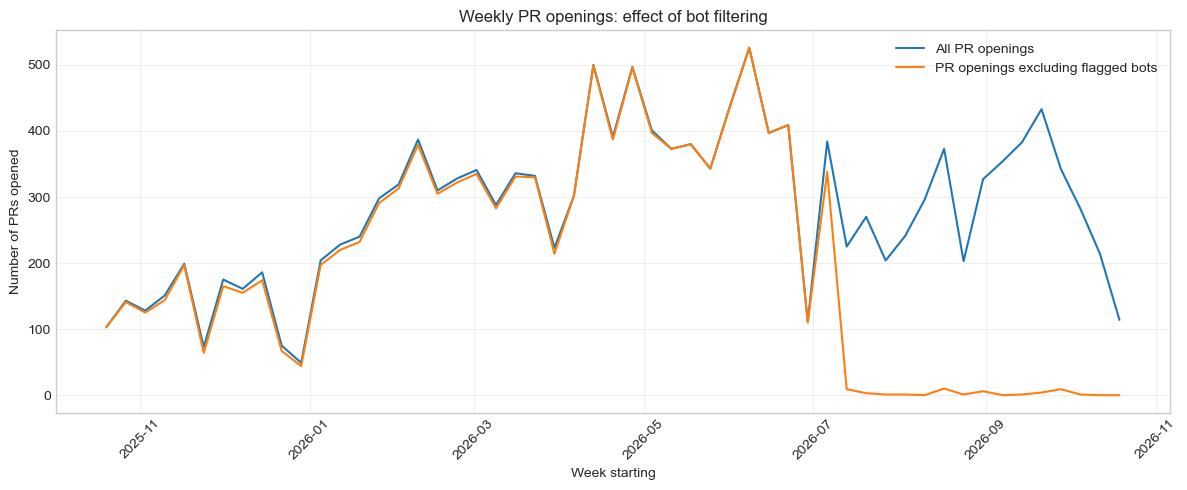

In [12]:
all_contributors = pd.read_csv("contributors.csv")
all_weekly = pd.read_csv("weekly.csv")
all_weekly["period_start"] = pd.to_datetime(
    all_weekly["period_start"], utc=True
)

is_bot = (
    all_contributors["bot_candidate"]
    .astype(str).str.lower().isin(["true", "1"])
)
bot_ids = all_contributors.loc[is_bot, "contributor_id"]

total = all_weekly.groupby("period_start")["pr_opened_count"].sum()

excluding_bots = (
    all_weekly.loc[~all_weekly["contributor_id"].isin(bot_ids)]
    .groupby("period_start")["pr_opened_count"]
    .sum()
    .reindex(total.index, fill_value=0)
)

plt.figure(figsize=(12, 5))
plt.plot(total.index, total, label="All PR openings")
plt.plot(
    excluding_bots.index,
    excluding_bots,
    label="PR openings excluding flagged bots"
)

plt.xlabel("Week starting")
plt.ylabel("Number of PRs opened")
plt.title("Weekly PR openings: effect of bot filtering")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [13]:
print("Identities with zero activities:",
      contributors["count_window"].eq(0).sum())
print("Identities with one activity:",
      contributors["count_window"].eq(1).sum())
print("Identities with two or more activities:",
      contributors["count_window"].ge(2).sum())

# Compare activity levels among contributors active in the window.
active = contributors.loc[contributors["count_window"] > 0]

display(
    active[["count_window", "active_weeks"]]
    .quantile([0.50, 0.75, 0.90, 0.95, 0.99])
    .rename_axis("Percentile")
)

Identities with zero activities: 1633
Identities with one activity: 21621
Identities with two or more activities: 4257


,count_window,active_weeks
Percentile,,
0.50,1.0,1.0
0.75,1.0,1.0
0.90,2.0,2.0
0.95,3.0,2.0
0.99,11.0,6.0
